# P4.06 — What identified money buys: funding the supply levers

**Questions:** RQ8.4 (which mix of spending, tax policy and investment improves affordability within fiscal constraints?), RQ8.6
(how should resources be allocated to maximise affordability gains per euro?). Builds on the simulator (`p4_02`), the excess vacant
homes (`p2_16`) and the vacant-home surcharge (`p3_08`).

`p4_02` ranks levers by gain per euro but takes the budget as given. Here the budget comes from somewhere identified: the revenue
of a surcharge on vacant homes (an upper bound, from `p3_08`) and a 10% rise in what the State spends on housing development and
allowances (1,615 EUR m in 2024, `p3_06`), against the 0.5 billion EUR a year of the `p4_02` reference. Each budget is spent on one lever at mid unit
cost (extra completions or renovation of vacant homes) from 2027 to 2035 in the baseline scenario, and the fall in the 2035 median
price-to-income is read against the rise in the baseline. Behavioural parameters are the simulator's (assumptions and literature), so the
gains are modelled, not estimated; the source of the money is not modelled (the surcharge is municipal revenue, the spending is central).

In [1]:
import pandas as pd

from pthousing.data import build_panel, interim
from pthousing.simulation import engine as E
from pthousing.simulation import funding, scenarios
from pthousing.viz import charts, style

style.apply_style()
A = scenarios.load()
panel = build_panel.read("panel_municipality_year")
nat = build_panel.read("national_quarterly")
forecast = pd.read_csv("../../reports/tables/p4/national_forecast.csv")
anc = E.anchors(panel, nat, forecast, A)
N, SEED = 1000, 2026
p = E.draw(A, N, SEED)
drift = E.calibrate(A, anc, p)
baseline = E.run(A, anc, "baseline", None, p, drift)
rise = baseline.end("pti_years") - anc.pti_years
print(
    f"baseline price-to-income {anc.pti_years:.1f} years in the start year, median rise to {A.end_year}: {pd.Series(rise).median():.2f} years"
)

baseline price-to-income 10.6 years in the start year, median rise to 2035: 4.58 years


## Step 1 — The budgets
The surcharge revenue is read from `p3_08` (extra IMI a year if a quarter, half or all of the excess vacant homes are classified
vacant). Housing spending is the 2024 value of `eurostat_housing_spending` (development plus allowances).

In [2]:
surcharge = pd.read_csv("../../reports/tables/p3/vacant_surcharge_revenue.csv")
spending = interim.read("eurostat_housing_spending")
pt = spending[(spending["geo"] == "PT") & (spending["year"] == 2024)].iloc[0]
housing = float(pt["housing_development_eur_m"] + pt["housing_benefits_eur_m"])
budgets = {
    **{
        f"Surcharge, {s:.0%} of excess classified vacant": m
        for s, m in zip(surcharge["classified_vacant_share"], surcharge["all_eur_m"], strict=True)
    },
    "10% more housing spending": 0.1 * housing,
    "Reference of p4_02": 500.0,
}
pd.Series(budgets, name="eur_m_a_year").round(0).to_frame()

,eur_m_a_year
"Surcharge, 25% of excess classified vacant",55.0
"Surcharge, 50% of excess classified vacant",111.0
"Surcharge, 100% of excess classified vacant",221.0
10% more housing spending,161.0
Reference of p4_02,500.0


## Step 2 — What each budget buys
Units a year, and the fall in the 2035 median price-to-income (years of income) with its 80% range over the draws, as a share of the
baseline rise.

In [3]:
rows = []
for name, eur_m in budgets.items():
    for lever, label in (
        ("construction_boost_units", "extra completions"),
        ("vacant_renovation_units", "renovated vacant homes"),
    ):
        r = funding.gain_for_budget(A, anc, "baseline", p, eur_m * 1e6, {lever: 1.0}, drift)
        rows.append(
            {
                "budget": name,
                "eur_m_a_year": eur_m,
                "lever": label,
                "units_a_year": r[lever],
                **r.drop(list(funding.UNIT_LEVERS)),
            }
        )
result = pd.DataFrame(rows)
style.save_table(result.round(3), "p4", "funding_gain_by_budget")
result[
    [
        "budget",
        "lever",
        "eur_m_a_year",
        "units_a_year",
        "gain_p10",
        "gain_p50",
        "gain_p90",
        "gain_share_of_rise_pct",
    ]
].round(2)

,budget,lever,eur_m_a_year,units_a_year,gain_p10,gain_p50,gain_p90,gain_share_of_rise_pct
0,"Surcharge, 25% of excess classified vacant",extra completions,55.30,2212.0,0.04,0.06,0.08,1.33
1,"Surcharge, 25% of excess classified vacant",renovated vacant homes,55.30,1106.0,0.03,0.04,0.05,0.79
2,"Surcharge, 50% of excess classified vacant",extra completions,110.60,4424.0,0.09,0.12,0.17,2.66
3,"Surcharge, 50% of excess classified vacant",renovated vacant homes,110.60,2212.0,0.05,0.07,0.10,1.57
4,"Surcharge, 100% of excess classified vacant",extra completions,221.20,8848.0,0.17,0.24,0.33,5.29
5,"Surcharge, 100% of excess classified vacant",renovated vacant homes,221.20,4424.0,0.10,0.14,0.20,3.14
6,10% more housing spending,extra completions,161.46,6458.4,0.12,0.18,0.24,3.87
7,10% more housing spending,renovated vacant homes,161.46,3229.2,0.08,0.11,0.14,2.29
8,Reference of p4_02,extra completions,500.00,20000.0,0.38,0.54,0.73,11.83
9,Reference of p4_02,renovated vacant homes,500.00,10000.0,0.24,0.32,0.44,7.05


WindowsPath('reports/figures/p4/funding_gain.png')

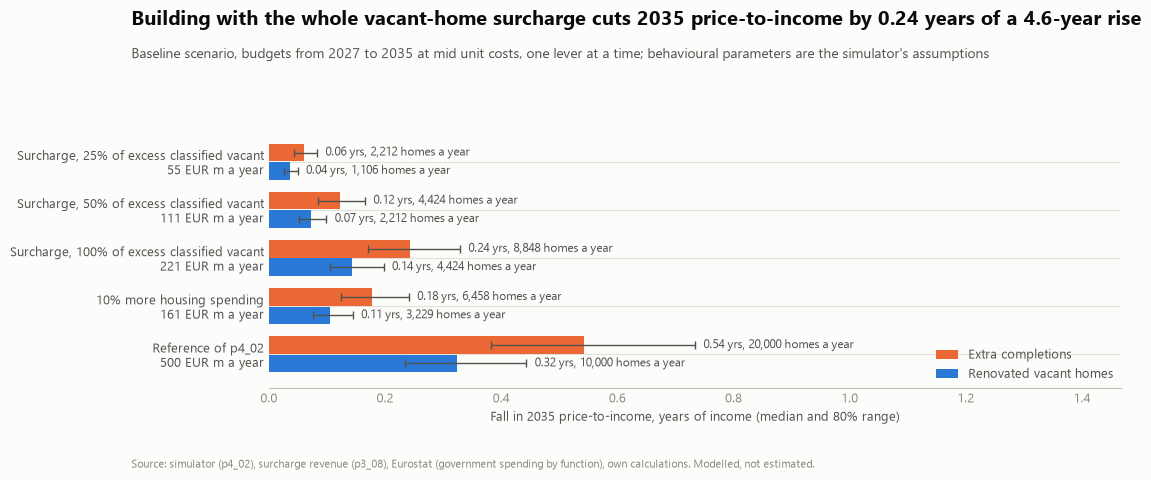

In [4]:
fig = charts.funding_gain(result, float(pd.Series(rise).median()))
style.save_fig(fig, "p4", "funding_gain")

## Key numbers

In [5]:
print(
    f"housing development plus allowances 2024: {housing:,.0f} EUR m; baseline rise of price-to-income {pd.Series(rise).median():.2f} years to {A.end_year}"
)
for _, r in result.iterrows():
    print(
        f"  {r.budget} ({r.eur_m_a_year:,.0f} EUR m): {r.lever} {r.units_a_year:,.0f} a year, gain {r.gain_p50:.2f} years "
        f"({r.gain_p10:.2f} to {r.gain_p90:.2f}), {r.gain_share_of_rise_pct:.1f}% of the rise"
    )

housing development plus allowances 2024: 1,615 EUR m; baseline rise of price-to-income 4.58 years to 2035
  Surcharge, 25% of excess classified vacant (55 EUR m): extra completions 2,212 a year, gain 0.06 years (0.04 to 0.08), 1.3% of the rise
  Surcharge, 25% of excess classified vacant (55 EUR m): renovated vacant homes 1,106 a year, gain 0.04 years (0.03 to 0.05), 0.8% of the rise
  Surcharge, 50% of excess classified vacant (111 EUR m): extra completions 4,424 a year, gain 0.12 years (0.09 to 0.17), 2.7% of the rise
  Surcharge, 50% of excess classified vacant (111 EUR m): renovated vacant homes 2,212 a year, gain 0.07 years (0.05 to 0.10), 1.6% of the rise
  Surcharge, 100% of excess classified vacant (221 EUR m): extra completions 8,848 a year, gain 0.24 years (0.17 to 0.33), 5.3% of the rise
  Surcharge, 100% of excess classified vacant (221 EUR m): renovated vacant homes 4,424 a year, gain 0.14 years (0.10 to 0.20), 3.1% of the rise
  10% more housing spending (161 EUR m): ext